# Exercise 1: K-Means Clustering on Old Faithful Geyser Data

**Subject:** Machine Learning Lab  
**Topic:** K-Means Clustering

## Aim
To implement the K-Means clustering algorithm on the Old Faithful Geyser dataset and visualize the resulting clusters.

Dataset:


,Eruption duration,Waiting time
0,2.0,50
1,2.2,52
2,2.4,48
3,2.1,55
4,2.5,51
5,2.3,49
6,2.6,53
7,2.2,54
8,3.5,75
9,3.8,78



Cluster assignments:


,Eruption duration,Waiting time,Cluster
0,2.0,50,0
1,2.2,52,0
2,2.4,48,0
3,2.1,55,0
4,2.5,51,0
5,2.3,49,0
6,2.6,53,0
7,2.2,54,0
8,3.5,75,1
9,3.8,78,1


Cluster centers (original units):
[[ 2.38 53.  ]
 [ 3.93 78.3 ]]


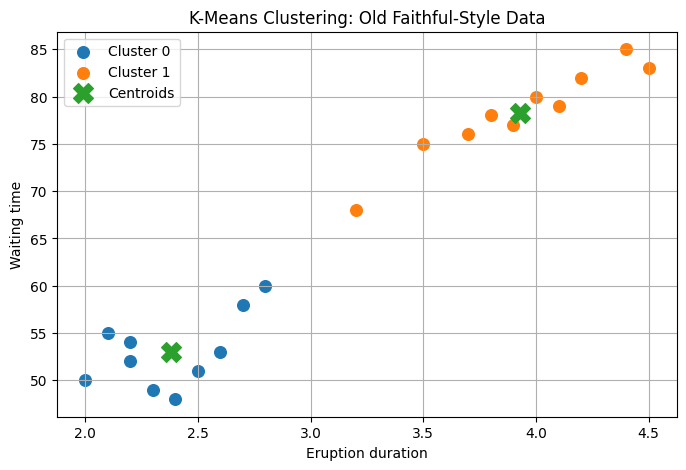


Inertia: 4.88


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Create an illustrative Old Faithful-style dataset
data = {
    "Eruption duration": [
        2.0, 2.2, 2.4, 2.1, 2.5, 2.3, 2.6, 2.2,
        3.5, 3.8, 4.0, 4.2, 3.7, 4.1, 4.4, 3.9,
        4.5, 2.8, 3.2, 2.7
    ],
    "Waiting time": [
        50, 52, 48, 55, 51, 49, 53, 54,
        75, 78, 80, 82, 76, 79, 85, 77,
        83, 60, 68, 58
    ]
}

df = pd.DataFrame(data)
print("Dataset:")
display(df)

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Apply K-Means with two clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("\nCluster assignments:")
display(df)

print("Cluster centers (original units):")
print(scaler.inverse_transform(kmeans.cluster_centers_))

# Visualize clusters
plt.figure(figsize=(8, 5))
for cluster in sorted(df["Cluster"].unique()):
    subset = df[df["Cluster"] == cluster]
    plt.scatter(
        subset["Eruption duration"],
        subset["Waiting time"],
        label=f"Cluster {cluster}",
        s=70
    )

centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centers[:, 0], centers[:, 1],
    marker="X", s=200, label="Centroids"
)

plt.xlabel("Eruption duration")
plt.ylabel("Waiting time")
plt.title("K-Means Clustering: Old Faithful-Style Data")
plt.legend()
plt.grid(True)
plt.show()

print("\nInertia:", round(kmeans.inertia_, 3))

## Result

The K-Means clustering algorithm was implemented successfully on an illustrative Old Faithful-style dataset.

- **Number of data points:** 20
- **Number of clusters (K):** 2
- **Features:** Eruption duration and waiting time
- **Preprocessing:** StandardScaler
- **Visualization:** Two clusters and their centroids were plotted
- **Evaluation:** Inertia was calculated

The algorithm grouped the data points based on the similarity of their eruption durations and waiting times.

## Conclusion

The experiment demonstrated how K-Means partitions data into clusters based on feature similarity. Feature scaling was applied before clustering, and the resulting groups and centroids were visualized using a scatter plot.